In [9]:
# Imports and paths
import os
import torch
import numpy as np
import h5py
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
import umap

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

PT_DIR = "/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/features/pt_files"

/home/ubuntu/miniconda3/envs/clam_latest/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 1. Extract

In [2]:
# Extract embeddings and track slide_id/patch_index

all_features = []
patch_index = []  # (slide_id, patch_idx)

for fname in sorted(os.listdir(PT_DIR)):
    if not fname.endswith(".pt"):
        continue

    slide_id = fname.replace(".pt", "")
    feats = torch.load(os.path.join(PT_DIR, fname))  # [N_patches, D]
    feats = feats.cpu().numpy()

    all_features.append(feats)
    patch_index.extend([(slide_id, i) for i in range(feats.shape[0])])

X = np.vstack(all_features)  # [N_total_patches, D]

print("Total patches:", X.shape[0])
print("Feature dim:", X.shape[1])


Total patches: 90942
Feature dim: 1024


# 2. Normalize

In [3]:
# Normalize 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# 3. PCA

In [4]:
# Fit full PCA and select number of components that reach 90% of variance explained
pca_full = PCA(random_state=0)
X_pca_full = pca_full.fit_transform(X_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)

n_components = np.where(cum_var >= 0.90)[0][0] + 1
print("Using n_components =", n_components)

Using n_components = 274


In [5]:
pca = PCA(n_components=n_components, random_state=0)
X_pca = pca.fit_transform(X_scaled)

# 4. Clustering

In [7]:
# Test K for kmeans clustering 
X_eval = X_pca   # shape: (N_patches, n_components)

Ks = range(10, 30)
sil_scores = []

# subsample if large
max_samples = 10000
if X_eval.shape[0] > max_samples:
    idx = np.random.choice(X_eval.shape[0], max_samples, replace=False)
    X_sub = X_eval[idx]
else:
    X_sub = X_eval

for k in Ks:
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=20)
    labels = kmeans.fit_predict(X_sub)
    score = silhouette_score(X_sub, labels)
    sil_scores.append(score)

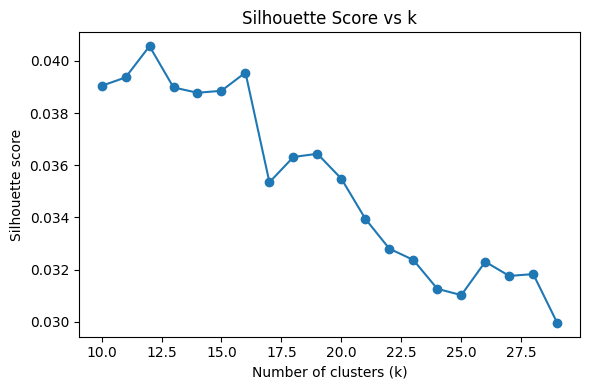

In [10]:
plt.figure(figsize=(6, 4))
plt.plot(Ks, sil_scores, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score vs k")
plt.tight_layout()
plt.show()

In [11]:
# Select k
k = 16

kmeans = KMeans(
    n_clusters=k,
    random_state=0,
    n_init=20
)

cluster_labels = kmeans.fit_predict(X_pca)  # [N_total_patches]

# 5. Visualization (UMAP)

In [24]:
# Visualize in a UMAP 

umap_model = umap.UMAP(
    n_neighbors=40,      # local vs global structure
    min_dist=0.3,        # cluster tightness
    n_components=2,
    metric="euclidean",
    random_state=42
)

X_umap = umap_model.fit_transform(X_pca)

print(X_umap.shape)  # (N_patches, 2)

/home/ubuntu/miniconda3/envs/clam_latest/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(90942, 2)


In [28]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap, BoundaryNorm

# Create discrete colormap with exactly n_clusters colors
cmap = ListedColormap(plt.cm.tab20.colors[:16])
# Boundaries so each integer cluster gets one color
bounds = np.arange(-0.5, 16 + 0.5, 1)
norm = BoundaryNorm(bounds, cmap.N)

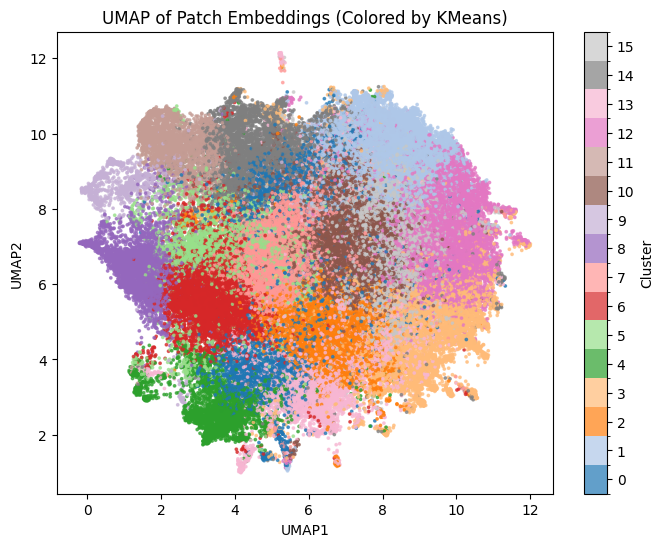

In [38]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=cluster_labels,
    cmap=cmap,
    norm=norm,
    s=3,
    alpha=0.7
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP of Patch Embeddings (Colored by KMeans)")

# Discrete colorbar with integer ticks
cbar = plt.colorbar(
    scatter,
    ticks=np.arange(16)
)
cbar.set_label("Cluster")

export_path = '/mnt/central_nas/rcc_volume/RCC/figures/HE/HE_embeddings_clusters_UMAP.pdf' 
plt.savefig(export_path, format = 'pdf')

plt.show()


# 6. Export

In [22]:
# Create output table
df_patches = pd.DataFrame(
    patch_index,
    columns=["slide_id", "patch_idx"]
)

df_patches["cluster"] = cluster_labels

print(df_patches.head())


         slide_id  patch_idx  cluster
0  ZTMA20.1_X10Y1          0        6
1  ZTMA20.1_X10Y1          1        2
2  ZTMA20.1_X10Y1          2        7
3  ZTMA20.1_X10Y1          3       13
4  ZTMA20.1_X10Y1          4        2


In [21]:
df_cluster_counts = (
    df_patches
    .groupby(["slide_id", "cluster"])
    .size()
    .unstack(fill_value=0)
)

print(df_cluster_counts.head())


cluster          0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  \
slide_id                                                                      
ZTMA20.1_X10Y1   25   0  13   7   0   1  10   5   6   0   3   0   0  20   1   
ZTMA20.1_X10Y10   6   0   0   0   0   8   2   5   2   0   4  46   0   0   6   
ZTMA20.1_X10Y11  25  30   0   0   0  12   3  11   7   0   0   0   8   0   0   
ZTMA20.1_X10Y12  66   0   0   3   2   4  14   0   1   0   0   2   0   0  16   
ZTMA20.1_X10Y13   1   0   0  47  36   0  21   1   2   0   0   0   0   0   1   

cluster          15  
slide_id             
ZTMA20.1_X10Y1   11  
ZTMA20.1_X10Y10   2  
ZTMA20.1_X10Y11   0  
ZTMA20.1_X10Y12   0  
ZTMA20.1_X10Y13   0  


In [23]:
df_patches.to_csv("/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/HE_clusters_slide.csv", index=False)